## 1. Load Mask, Filter Noise (Objek Terbesar) & Ground Truth
Pada bagian ini kita memuat citra mask prediksi berdasarkan `SAMPLE_FILE`, membersihkan fragmen/noise kecil dengan mengambil region terbesar (`largest_region` → `clean_binary`), serta mencocokkan dan memuat citra Ground Truth (`gt`).

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import measure
from skimage.morphology import convex_hull_image

# Ganti dengan nama file polip yang ingin kamu analisis
SAMPLE_FILE = "cju2r6mt2om21099352pny5gw_mask.png"
BASE_DIR = "Berhasil"
FOLDER_MASK = os.path.join(BASE_DIR, "Hasil_Segmentasi", "Mask_Biner")
FOLDER_SEG  = os.path.join(BASE_DIR, "Hasil_Segmentasi", "Objek_RGB")
FOLDER_GT   = os.path.join(BASE_DIR, "Datasets", "Masks")

# --- Load Mask & Filter Noise ---
mask_path = os.path.join(FOLDER_MASK, SAMPLE_FILE)
if not os.path.exists(mask_path):
    raise FileNotFoundError(f"File mask tidak ditemukan: {mask_path}")

mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
binary = (mask > 127).astype(np.uint8)

label_image = measure.label(binary)
regions = measure.regionprops(label_image)
if len(regions) == 0:
    raise ValueError("Tidak ada objek terdeteksi pada mask biner.")

regions.sort(key=lambda x: x.area, reverse=True)
largest_region = regions[0]
clean_binary = (label_image == largest_region.label)

# Opsional: load citra segmentasi RGB jika tersedia
STEM = SAMPLE_FILE.replace('_mask.png', '')
seg_path = os.path.join(FOLDER_SEG, STEM + '_seg.png')
seg = None
if os.path.exists(seg_path):
    seg_bgr = cv2.imread(seg_path)
    if seg_bgr is not None:
        seg = cv2.cvtColor(seg_bgr, cv2.COLOR_BGR2RGB)

# --- Cari & Load Ground Truth (GT) ---
gt_path = None
for ext in ['.png', '.jpg', '.jpeg']:
    potential_gt = os.path.join(FOLDER_GT, STEM + ext)
    if os.path.exists(potential_gt):
        gt_path = potential_gt
        break

if gt_path is None:
    raise FileNotFoundError(f"Ground Truth untuk {STEM} tidak ditemukan di {FOLDER_GT}")

gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)
if gt.shape != mask.shape:
    gt = cv2.resize(gt, (mask.shape[1], mask.shape[0]), interpolation=cv2.INTER_NEAREST)

print(f"Sampel: {STEM}")
print(f"GT Path: {gt_path}")
print(f"Ukuran Mask: {mask.shape}, GT: {gt.shape}")
print("Berhasil load gambar dan mengekstrak properti dasar.")

Sampel: cju2r6mt2om21099352pny5gw
GT Path: Berhasil\Datasets\Masks\cju2r6mt2om21099352pny5gw.jpg
Ukuran Mask: (528, 608), GT: (528, 608)
Berhasil load gambar dan mengekstrak properti dasar.


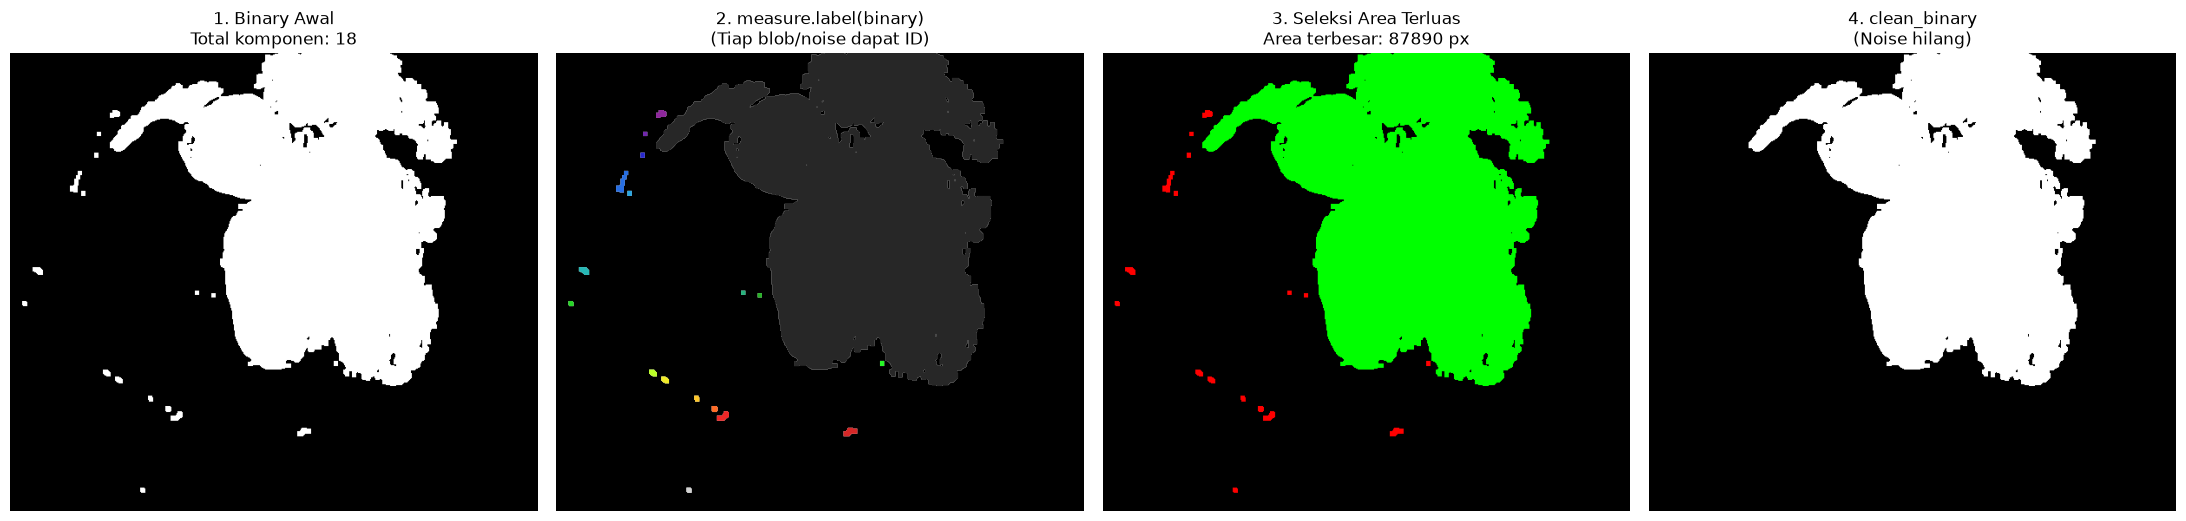

In [2]:
# --- Visualisasi Tahapan Load Mask & Filter Noise ---
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

# 1. Mask Biner Awal (masih ada noise/bintik kecil)
axes[0].imshow(binary, cmap='gray')
axes[0].set_title(f"1. Binary Awal\nTotal komponen: {len(regions)}")
axes[0].axis('off')

# 2. Hasil measure.label(binary) -> tiap region punya label angka berbeda
# Gunakan colormap 'nipy_spectral' atau 'tab20' agar tiap label terlihat beda warna
label_vis = np.ma.masked_where(label_image == 0, label_image)
axes[1].imshow(binary, cmap='gray')
im_lbl = axes[1].imshow(label_vis, cmap='nipy_spectral', alpha=0.85)
axes[1].set_title("2. measure.label(binary)\n(Tiap blob/noise dapat ID)")
axes[1].axis('off')

# 3. Highlight Largest Region (komponen terluas yang dipilih)
largest_vis = np.zeros((*binary.shape, 3), dtype=np.uint8)
largest_vis[clean_binary] = [0, 255, 0]       # Hijau = objek utama (terluas)
other_noise = (binary > 0) & (~clean_binary)
largest_vis[other_noise] = [255, 0, 0]        # Merah = komponen lain / noise

axes[2].imshow(largest_vis)
axes[2].set_title(f"3. Seleksi Area Terluas\nArea terbesar: {largest_region.area:.0f} px")
axes[2].axis('off')

# 4. Clean Binary Akhir (noise merah sudah dibuang)
axes[3].imshow(clean_binary, cmap='gray')
axes[3].set_title("4. clean_binary\n(Noise hilang)")
axes[3].axis('off')

plt.tight_layout()
plt.show()

### Apa yang Terlihat di Tiap Panel?

* **Binary Awal:** Menampilkan hasil *thresholding* `mask > 127`, termasuk bintik-bintik putih kecil di luar objek utama[cite: 2].
* **`measure.label(binary)`:** Menampilkan hasil pelabelan komponen terhubung—setiap kelompok piksel putih yang terpisah diberi nomor label sendiri (`1, 2, 3, ...`) sehingga *noise* kecil punya label terpisah dari objek utama.
* **Seleksi Area Terluas:** Menunjukkan hasil `regions.sort(key=lambda x: x.area, reverse=True)` dan `largest_region = regions[0]`. Bagian **hijau** adalah *region* terluas yang dipertahankan, sedangkan bagian **merah** adalah komponen/*noise* lain yang akan dibuang.
* **`clean_binary`:** Hasil akhir `(label_image == largest_region.label)`—hanya menyisakan komponen terluas sehingga *noise* kecil sudah bersih[cite: 1, 2].

## 2. Evaluasi Mask & Visualisasi Overlay
Menghitung metrik **IoU**, **Dice**, **Precision**, dan **Recall** antara mask prediksi (`mask`) dan Ground Truth (`gt`), lalu menampilkan perbandingan visual serta peta overlay:
- **Hijau (TP):** True Positive (terdeteksi benar sebagai polip)
- **Merah (FP):** False Positive (salah terdeteksi sebagai polip)
- **Biru (FN):** False Negative (polip terlewat / tidak terdeteksi)

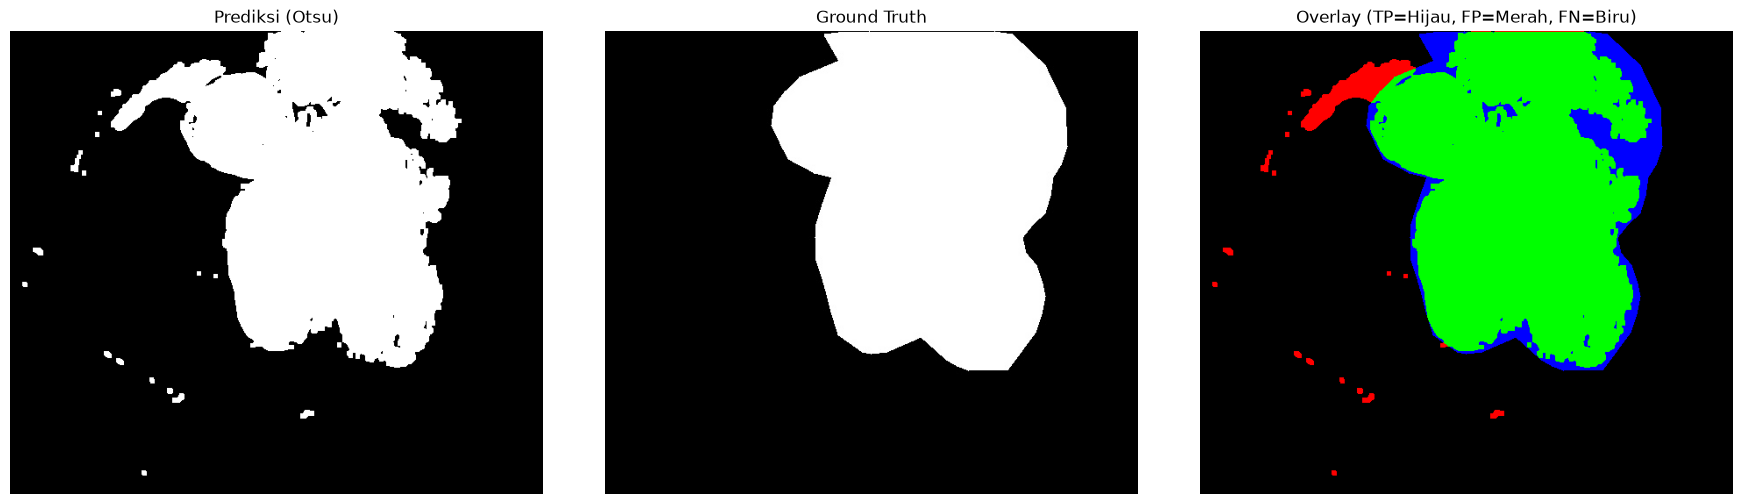

IoU: 0.8251 | Dice: 0.9041 | Precision: 0.9500 | Recall: 0.8625


In [3]:
def evaluate_mask(pred, gt):
    p = (pred > 127).astype(np.uint8)
    g = (gt   > 127).astype(np.uint8)
    inter = np.logical_and(p, g).sum()
    union = np.logical_or(p, g).sum()
    iou  = inter / union if union > 0 else 0.0
    dice = 2 * inter / (p.sum() + g.sum()) if (p.sum() + g.sum()) > 0 else 0.0
    prec = inter / p.sum() if p.sum() > 0 else 0.0
    rec  = inter / g.sum() if g.sum() > 0 else 0.0
    return {"IoU": iou, "Dice": dice, "Precision": prec, "Recall": rec}

metrics = evaluate_mask(mask, gt)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].imshow(mask, cmap='gray')
axes[0].set_title("Prediksi (Otsu)")
axes[0].axis('off')

axes[1].imshow(gt, cmap='gray')
axes[1].set_title("Ground Truth")
axes[1].axis('off')

overlay = np.zeros((*mask.shape, 3), dtype=np.uint8)
overlay[(mask > 127) & (gt > 127)] = [0, 255, 0]   # True Positive (Hijau)
overlay[(mask > 127) & (gt <= 127)] = [255, 0, 0]  # False Positive (Merah)
overlay[(mask <= 127) & (gt > 127)] = [0, 0, 255]  # False Negative (Biru)
axes[2].imshow(overlay)
axes[2].set_title("Overlay (TP=Hijau, FP=Merah, FN=Biru)")
axes[2].axis('off')

plt.tight_layout()
plt.show()

print(f"IoU: {metrics['IoU']:.4f} | Dice: {metrics['Dice']:.4f} | Precision: {metrics['Precision']:.4f} | Recall: {metrics['Recall']:.4f}")

## 3. Fitur Bentuk: Bounding Box, Convex Hull & Sumbu Utama/Minor
Menampilkan tiga visualisasi geometri utama pada objek polip bersih (`clean_binary`):
1. **Bounding Box** beserta nilai **Extent**.
2. **Convex Hull (Garis Kuning)** beserta nilai **Solidity**.
3. **Sumbu Utama (Kuning)**, **Sumbu Minor (Cyan)**, **Centroid (Titik Merah)**, dan **Aspect Ratio**.

C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_25040\2585939144.py:25: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  x1 = x0 - 0.5 * largest_region.major_axis_length * np.sin(orientation)
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_25040\2585939144.py:26: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  y1 = y0 + 0.5 * largest_region.major_axis_length * np.cos(orientation)
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_25040\2585939144.py:27: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  x2 = x0 + 0.5 * largest_region.major_axis_length * np.sin(orientation)
C:\Users\Talitha Su

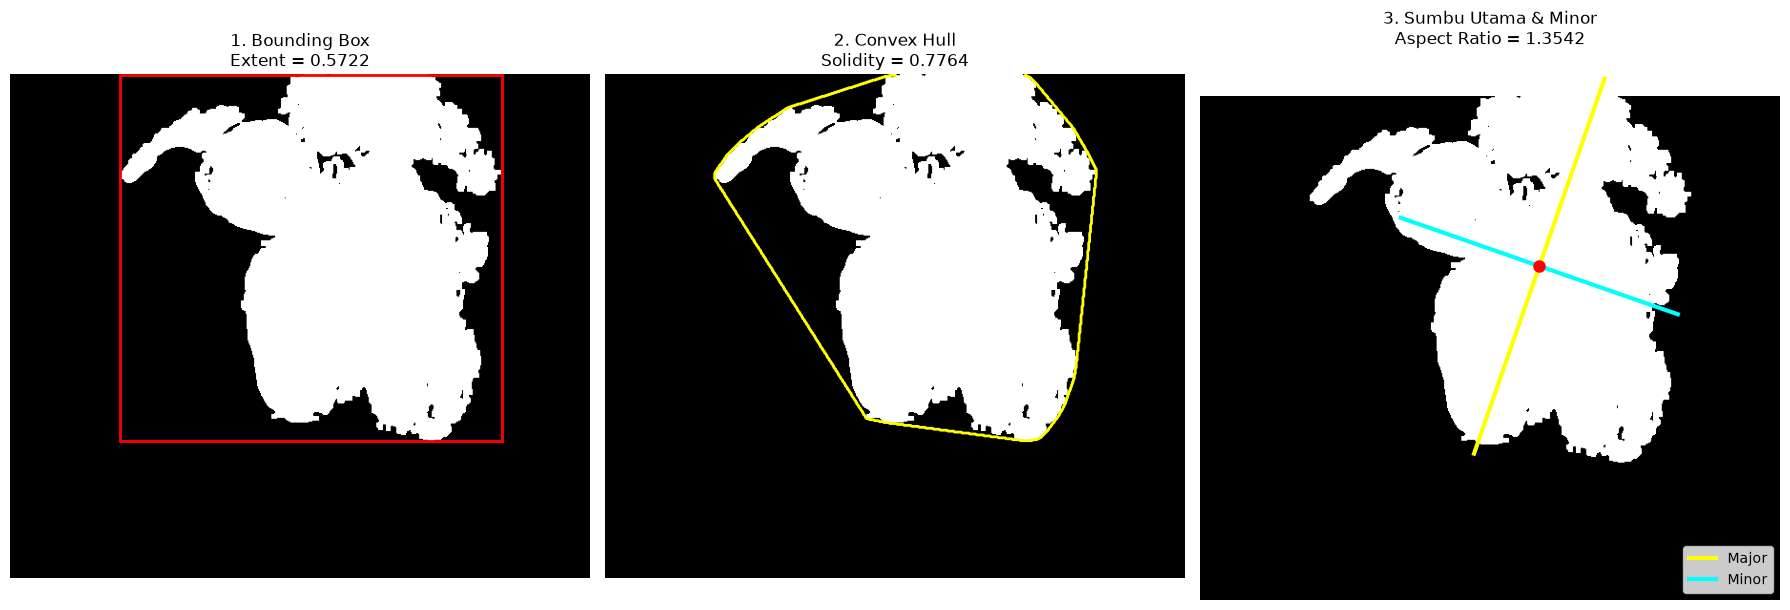

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# (1) Bounding Box
ax = axes[0]
ax.imshow(clean_binary, cmap='gray')
minr, minc, maxr, maxc = largest_region.bbox
rect = plt.Rectangle((minc, minr), maxc - minc, maxr - minr, fill=False, edgecolor='red', linewidth=2)
ax.add_patch(rect)
ax.set_title(f"1. Bounding Box\nExtent = {largest_region.extent:.4f}")
ax.axis('off')

# (2) Convex Hull
ax = axes[1]
hull_3 = convex_hull_image(clean_binary)
ax.imshow(clean_binary, cmap='gray')
ax.contour(hull_3, colors='yellow', linewidths=2)
ax.set_title(f"2. Convex Hull\nSolidity = {largest_region.solidity:.4f}")
ax.axis('off')

# (3) Sumbu Utama & Minor
ax = axes[2]
ax.imshow(clean_binary, cmap='gray')
y0, x0 = largest_region.centroid
orientation = largest_region.orientation
x1 = x0 - 0.5 * largest_region.major_axis_length * np.sin(orientation)
y1 = y0 + 0.5 * largest_region.major_axis_length * np.cos(orientation)
x2 = x0 + 0.5 * largest_region.major_axis_length * np.sin(orientation)
y2 = y0 - 0.5 * largest_region.major_axis_length * np.cos(orientation)
ax.plot([x1, x2], [y1, y2], '-', color='yellow', linewidth=3, label='Major')

x3 = x0 - 0.5 * largest_region.minor_axis_length * np.cos(orientation)
y3 = y0 - 0.5 * largest_region.minor_axis_length * np.sin(orientation)
x4 = x0 + 0.5 * largest_region.minor_axis_length * np.cos(orientation)
y4 = y0 + 0.5 * largest_region.minor_axis_length * np.sin(orientation)
ax.plot([x3, x4], [y3, y4], '-', color='cyan', linewidth=3, label='Minor')

ax.plot(x0, y0, 'ro', markersize=8)
aspect_ratio = (
    largest_region.major_axis_length / largest_region.minor_axis_length
    if largest_region.minor_axis_length > 0 else 0.0
)
ax.set_title(f"3. Sumbu Utama & Minor\nAspect Ratio = {aspect_ratio:.4f}")
ax.legend(loc='lower right')
ax.axis('off')

plt.tight_layout()
plt.show()

## 4. Fitur Bentuk: Convex Hull (Garis Merah) & Feret's Diameter
Menampilkan **Convex Hull (Garis Merah)** dengan perhitungan eksplisit `solidity_clean = area_polip / area_hull` serta nilai **Max Feret Diameter** (jarak ujung ke ujung terjauh dalam satuan piksel) pada objek polip bersih.

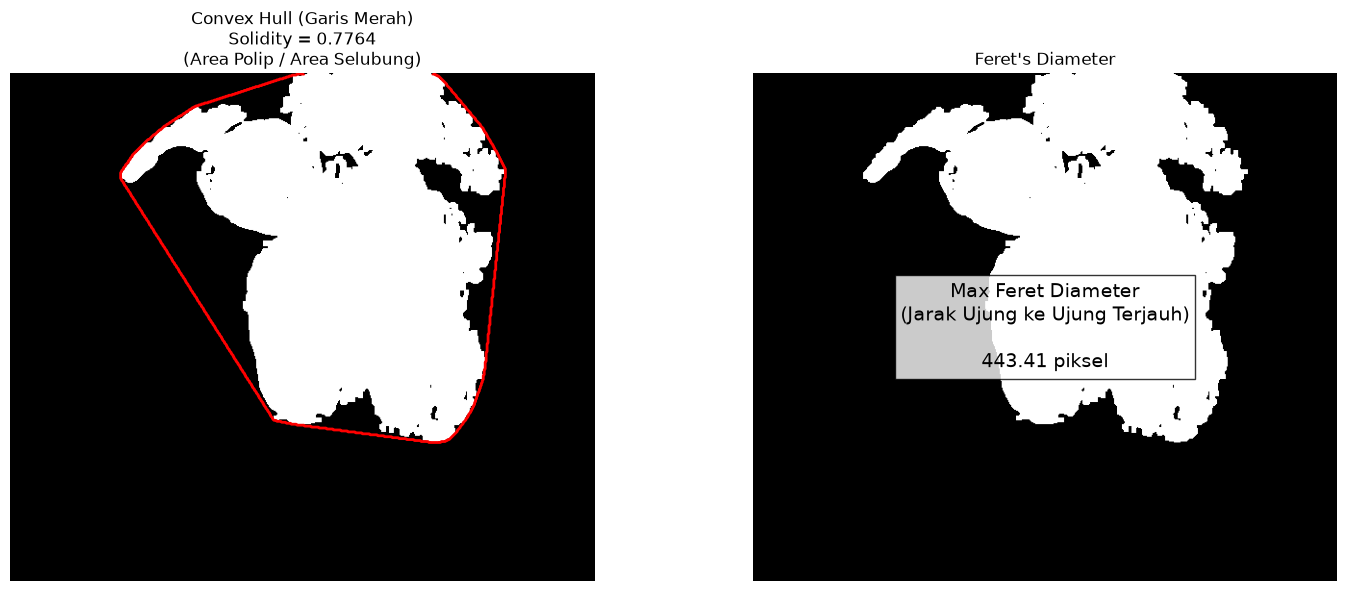

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Convex Hull (Garis Merah) pada clean_binary
ax = axes[0]
hull = convex_hull_image(clean_binary)
ax.imshow(clean_binary, cmap='gray')
ax.contour(hull, colors='red', linewidths=2)

area_polip = largest_region.area
area_hull = np.sum(hull)
solidity_clean = area_polip / area_hull if area_hull > 0 else 0.0

ax.set_title(f"Convex Hull (Garis Merah)\nSolidity = {solidity_clean:.4f}\n(Area Polip / Area Selubung)")
ax.axis('off')

# Feret's Diameter
ax = axes[1]
ax.imshow(clean_binary, cmap='gray')

feret_max_clean = largest_region.feret_diameter_max

ax.text(
    0.5, 0.5,
    f"Max Feret Diameter\n(Jarak Ujung ke Ujung Terjauh)\n\n{feret_max_clean:.2f} piksel",
    transform=ax.transAxes, fontsize=14, ha='center', va='center',
    bbox=dict(facecolor='white', alpha=0.8)
)
ax.set_title("Feret's Diameter")
ax.axis('off')

plt.tight_layout()
plt.show()

## Ringkasan Visualisasi Gabungan (1 Image Full)
Menyatukan seluruh hasil analisis dalam satu kanvas (`2x3`):
- **Baris 1:** Prediksi (Otsu), Ground Truth, dan Overlay Evaluasi (TP/FP/FN).
- **Baris 2:** Bounding Box (`Extent`), Convex Hull (`Solidity`), dan Sumbu Utama/Minor (`Aspect Ratio` + `Max Feret Diameter`).

C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_25040\1089663527.py:8: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  if largest_region.minor_axis_length > 0 else 0.0
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_25040\1089663527.py:7: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  largest_region.major_axis_length / largest_region.minor_axis_length
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_25040\1089663527.py:7: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  largest_region.major_axis_length / largest_region.minor_axis_length
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykerne

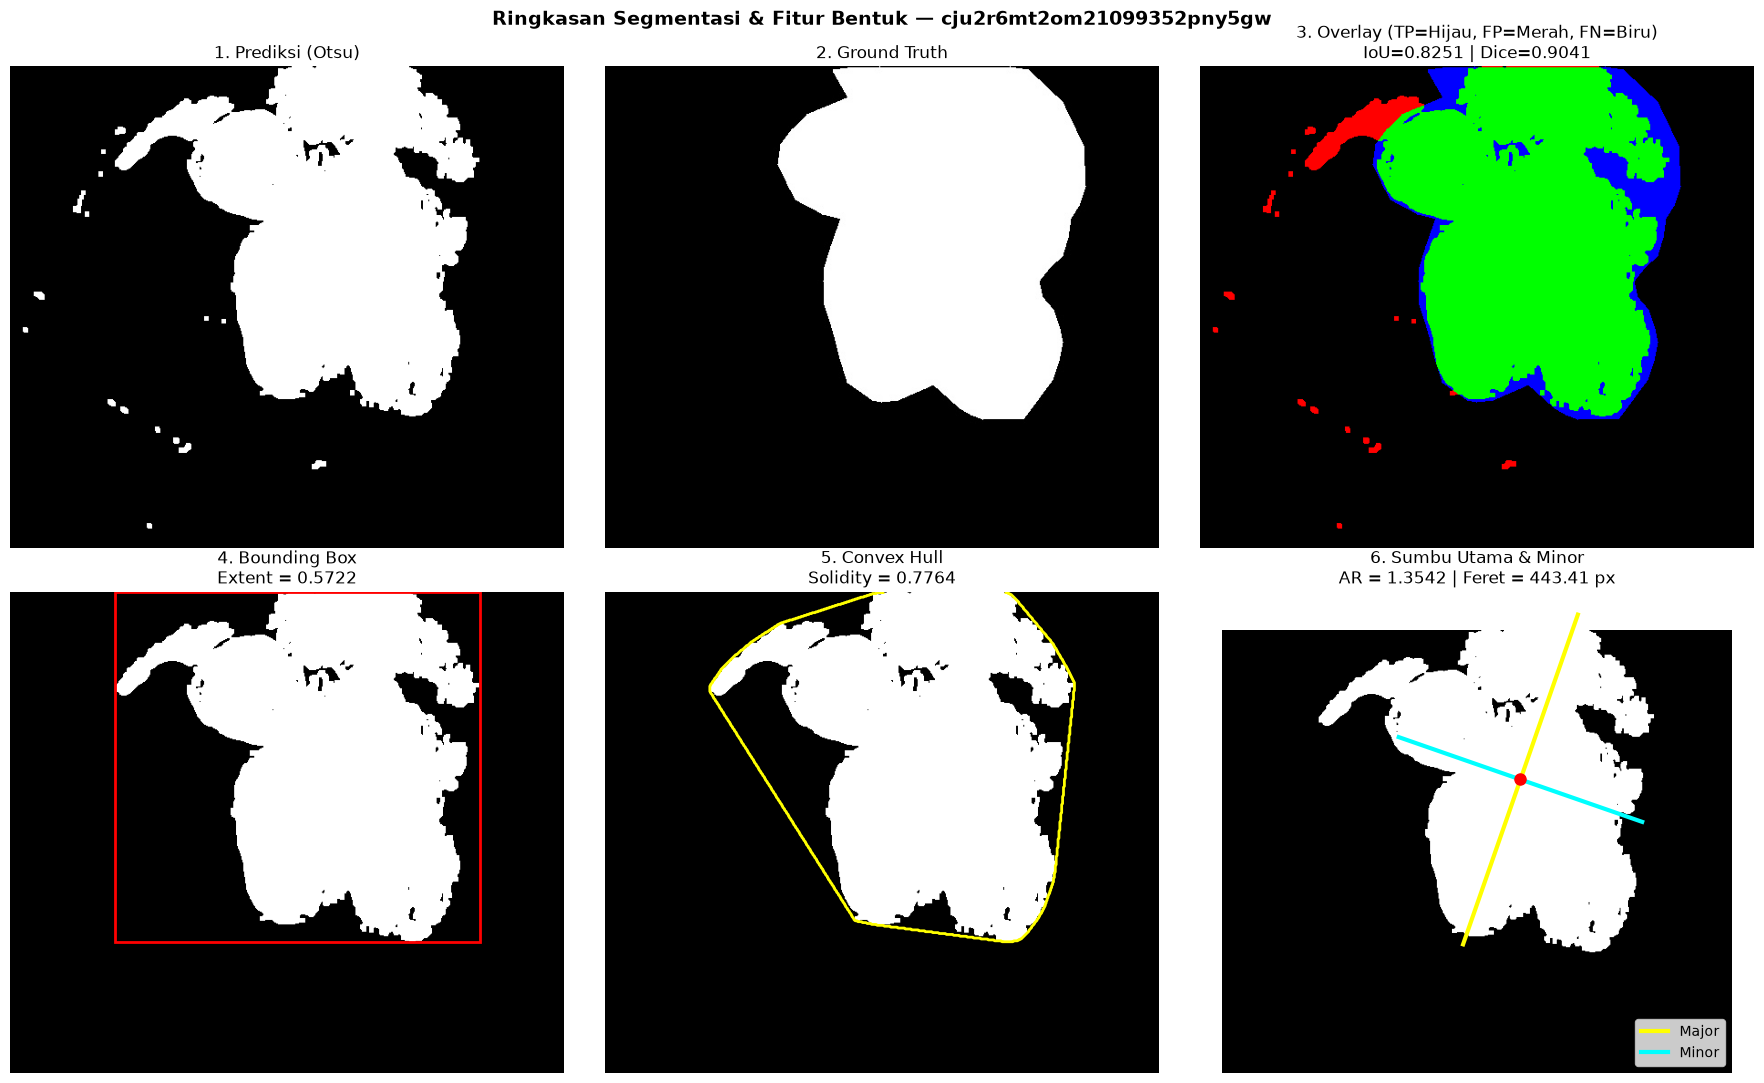

In [6]:
hull = convex_hull_image(clean_binary)
area_polip = largest_region.area
area_hull = np.sum(hull)
solidity = area_polip / area_hull if area_hull > 0 else 0.0
feret_max = largest_region.feret_diameter_max
aspect_ratio = (
    largest_region.major_axis_length / largest_region.minor_axis_length
    if largest_region.minor_axis_length > 0 else 0.0
)

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

# 1. Prediksi
axes[0, 0].imshow(mask, cmap='gray')
axes[0, 0].set_title("1. Prediksi (Otsu)")
axes[0, 0].axis('off')

# 2. Ground Truth
axes[0, 1].imshow(gt, cmap='gray')
axes[0, 1].set_title("2. Ground Truth")
axes[0, 1].axis('off')

# 3. Overlay TP / FP / FN
overlay = np.zeros((*mask.shape, 3), dtype=np.uint8)
overlay[(mask > 127) & (gt > 127)] = [0, 255, 0]   # TP (Hijau)
overlay[(mask > 127) & (gt <= 127)] = [255, 0, 0]  # FP (Merah)
overlay[(mask <= 127) & (gt > 127)] = [0, 0, 255]  # FN (Biru)
axes[0, 2].imshow(overlay)
axes[0, 2].set_title(
    f"3. Overlay (TP=Hijau, FP=Merah, FN=Biru)\n"
    f"IoU={metrics['IoU']:.4f} | Dice={metrics['Dice']:.4f}"
)
axes[0, 2].axis('off')

# 4. Bounding Box & Extent
ax = axes[1, 0]
ax.imshow(clean_binary, cmap='gray')
minr, minc, maxr, maxc = largest_region.bbox
rect = plt.Rectangle(
    (minc, minr), maxc - minc, maxr - minr,
    fill=False, edgecolor='red', linewidth=2
)
ax.add_patch(rect)
ax.set_title(f"4. Bounding Box\nExtent = {largest_region.extent:.4f}")
ax.axis('off')

# 5. Convex Hull (1 saja) & Solidity
ax = axes[1, 1]
ax.imshow(clean_binary, cmap='gray')
ax.contour(hull, colors='yellow', linewidths=2)
ax.set_title(f"5. Convex Hull\nSolidity = {solidity:.4f}")
ax.axis('off')

# 6. Sumbu Utama & Minor + Aspect Ratio & Feret Diameter
ax = axes[1, 2]
ax.imshow(clean_binary, cmap='gray')
y0, x0 = largest_region.centroid
orientation = largest_region.orientation

x1 = x0 - 0.5 * largest_region.major_axis_length * np.sin(orientation)
y1 = y0 + 0.5 * largest_region.major_axis_length * np.cos(orientation)
x2 = x0 + 0.5 * largest_region.major_axis_length * np.sin(orientation)
y2 = y0 - 0.5 * largest_region.major_axis_length * np.cos(orientation)
ax.plot([x1, x2], [y1, y2], '-', color='yellow', linewidth=3, label='Major')

x3 = x0 - 0.5 * largest_region.minor_axis_length * np.cos(orientation)
y3 = y0 - 0.5 * largest_region.minor_axis_length * np.sin(orientation)
x4 = x0 + 0.5 * largest_region.minor_axis_length * np.cos(orientation)
y4 = y0 + 0.5 * largest_region.minor_axis_length * np.sin(orientation)
ax.plot([x3, x4], [y3, y4], '-', color='cyan', linewidth=3, label='Minor')

ax.plot(x0, y0, 'ro', markersize=8)
ax.set_title(
    f"6. Sumbu Utama & Minor\n"
    f"AR = {aspect_ratio:.4f} | Feret = {feret_max:.2f} px"
)
ax.legend(loc='lower right')
ax.axis('off')

plt.suptitle(f"Ringkasan Segmentasi & Fitur Bentuk — {STEM}", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

SAVE FILEE ALL

In [ ]:

# import os
# import cv2
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from skimage import measure
# from skimage.morphology import convex_hull_image

# BASE_DIR = "Berhasil"
# FOLDER_MASK = os.path.join(BASE_DIR, "Hasil_Segmentasi", "Mask_Biner")
# FOLDER_GT   = os.path.join(BASE_DIR, "Datasets", "Masks")
# FOLDER_OUT  = os.path.join(BASE_DIR, "Ekstrasi_Fitur")

# os.makedirs(FOLDER_OUT, exist_ok=True)


# def evaluate_mask(pred, gt):
#     p = (pred > 127).astype(np.uint8)
#     g = (gt   > 127).astype(np.uint8)
#     inter = np.logical_and(p, g).sum()
#     union = np.logical_or(p, g).sum()
#     iou  = inter / union if union > 0 else 0.0
#     dice = 2 * inter / (p.sum() + g.sum()) if (p.sum() + g.sum()) > 0 else 0.0
#     prec = inter / p.sum() if p.sum() > 0 else 0.0
#     rec  = inter / g.sum() if g.sum() > 0 else 0.0
#     return {"IoU": iou, "Dice": dice, "Precision": prec, "Recall": rec}


# def find_gt_path(stem, gt_folder):
#     for ext in [".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"]:
#         candidate = os.path.join(gt_folder, stem + ext)
#         if os.path.exists(candidate):
#             return candidate
#     return None


# mask_files = sorted([
#     f for f in os.listdir(FOLDER_MASK)
#     if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"))
# ])

# if len(mask_files) == 0:
#     raise ValueError(f"Tidak ada file gambar di {FOLDER_MASK}")

# records = []
# skipped = []

# for idx, sample_file in enumerate(mask_files, start=1):
#     stem = os.path.splitext(sample_file)[0]
#     if stem.endswith("_mask"):
#         stem = stem[:-5]

#     mask_path = os.path.join(FOLDER_MASK, sample_file)
#     gt_path = find_gt_path(stem, FOLDER_GT)

#     if gt_path is None:
#         skipped.append((sample_file, "GT tidak ditemukan"))
#         continue

#     mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
#     gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)

#     if mask is None or gt is None:
#         skipped.append((sample_file, "Gagal membaca gambar mask/GT"))
#         continue

#     if gt.shape != mask.shape:
#         gt = cv2.resize(gt, (mask.shape[1], mask.shape[0]), interpolation=cv2.INTER_NEAREST)

#     binary = (mask > 127).astype(np.uint8)
#     label_image = measure.label(binary)
#     regions = measure.regionprops(label_image)

#     if len(regions) == 0:
#         skipped.append((sample_file, "Tidak ada objek terdeteksi pada mask"))
#         continue

#     regions.sort(key=lambda r: r.area, reverse=True)
#     largest_region = regions[0]
#     clean_binary = (label_image == largest_region.label)

#     # Hitung metrik & fitur bentuk
#     metrics = evaluate_mask(mask, gt)
#     hull = convex_hull_image(clean_binary)
#     area_polip = float(largest_region.area)
#     area_hull = float(np.sum(hull))
#     solidity = area_polip / area_hull if area_hull > 0 else 0.0
#     extent = float(largest_region.extent)
#     feret_max = float(largest_region.feret_diameter_max)
#     major_axis = float(largest_region.major_axis_length)
#     minor_axis = float(largest_region.minor_axis_length)
#     aspect_ratio = major_axis / minor_axis if minor_axis > 0 else 0.0

#     # Buat 1 image gabungan (2x3)
#     fig, axes = plt.subplots(2, 3, figsize=(18, 11))

#     # 1. Prediksi
#     axes[0, 0].imshow(mask, cmap="gray")
#     axes[0, 0].set_title("1. Prediksi (Otsu)")
#     axes[0, 0].axis("off")

#     # 2. Ground Truth
#     axes[0, 1].imshow(gt, cmap="gray")
#     axes[0, 1].set_title("2. Ground Truth")
#     axes[0, 1].axis("off")

#     # 3. Overlay TP / FP / FN
#     overlay = np.zeros((*mask.shape, 3), dtype=np.uint8)
#     overlay[(mask > 127) & (gt > 127)] = [0, 255, 0]   # TP (Hijau)
#     overlay[(mask > 127) & (gt <= 127)] = [255, 0, 0]  # FP (Merah)
#     overlay[(mask <= 127) & (gt > 127)] = [0, 0, 255]  # FN (Biru)
#     axes[0, 2].imshow(overlay)
#     axes[0, 2].set_title(
#         f"3. Overlay (TP=Hijau, FP=Merah, FN=Biru)\n"
#         f"IoU={metrics['IoU']:.4f} | Dice={metrics['Dice']:.4f}"
#     )
#     axes[0, 2].axis("off")

#     # 4. Bounding Box & Extent
#     ax = axes[1, 0]
#     ax.imshow(clean_binary, cmap="gray")
#     minr, minc, maxr, maxc = largest_region.bbox
#     rect = plt.Rectangle(
#         (minc, minr), maxc - minc, maxr - minr,
#         fill=False, edgecolor="red", linewidth=2
#     )
#     ax.add_patch(rect)
#     ax.set_title(f"4. Bounding Box\nExtent = {extent:.4f}")
#     ax.axis("off")

#     # 5. Convex Hull (1 saja) & Solidity
#     ax = axes[1, 1]
#     ax.imshow(clean_binary, cmap="gray")
#     ax.contour(hull, colors="yellow", linewidths=2)
#     ax.set_title(f"5. Convex Hull\nSolidity = {solidity:.4f}")
#     ax.axis("off")

#     # 6. Sumbu Utama & Minor + Aspect Ratio & Feret Diameter
#     ax = axes[1, 2]
#     ax.imshow(clean_binary, cmap="gray")
#     y0, x0 = largest_region.centroid
#     orientation = largest_region.orientation

#     x1 = x0 - 0.5 * major_axis * np.sin(orientation)
#     y1 = y0 + 0.5 * major_axis * np.cos(orientation)
#     x2 = x0 + 0.5 * major_axis * np.sin(orientation)
#     y2 = y0 - 0.5 * major_axis * np.cos(orientation)
#     ax.plot([x1, x2], [y1, y2], "-", color="yellow", linewidth=3, label="Major")

#     x3 = x0 - 0.5 * minor_axis * np.cos(orientation)
#     y3 = y0 - 0.5 * minor_axis * np.sin(orientation)
#     x4 = x0 + 0.5 * minor_axis * np.cos(orientation)
#     y4 = y0 + 0.5 * minor_axis * np.sin(orientation)
#     ax.plot([x3, x4], [y3, y4], "-", color="cyan", linewidth=3, label="Minor")

#     ax.plot(x0, y0, "ro", markersize=8)
#     ax.text(
#         0.04, 0.94,
#         f"Max Feret: {feret_max:.2f} px",
#         transform=ax.transAxes, fontsize=11, fontweight="bold",
#         va="top", ha="left",
#         bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="black", alpha=0.85)
#     )
#     ax.set_title(
#         f"6. Sumbu Utama & Minor\n"
#         f"Aspect Ratio = {aspect_ratio:.4f} | Feret = {feret_max:.2f} px"
#     )
#     ax.legend(loc="lower right")
#     ax.axis("off")

#     plt.suptitle(
#         f"Ringkasan Segmentasi & Fitur Bentuk — {stem}  |  Max Feret Diameter: {feret_max:.2f} px",
#         fontsize=14, fontweight="bold"
#     )
#     plt.tight_layout()

#     out_img_path = os.path.join(FOLDER_OUT, f"{stem}_gabungan.png")
#     plt.savefig(out_img_path, dpi=150, bbox_inches="tight")
#     plt.close(fig)

#     records.append({
#         "sample": stem,
#         "mask_file": sample_file,
#         "gt_file": os.path.basename(gt_path),
#         "iou": metrics["IoU"],
#         "dice": metrics["Dice"],
#         "precision": metrics["Precision"],
#         "recall": metrics["Recall"],
#         "area_px": area_polip,
#         "extent": extent,
#         "solidity": solidity,
#         "major_axis_length": major_axis,
#         "minor_axis_length": minor_axis,
#         "aspect_ratio": aspect_ratio,
#         "feret_diameter_max_px": feret_max,
#     })

#     print(f"[{idx}/{len(mask_files)}] Tersimpan: {out_img_path}")

# # Simpan rekap fitur & metrik ke CSV
# if len(records) > 0:
#     df_hasil = pd.DataFrame(records)
#     csv_path = os.path.join(FOLDER_OUT, "ringkasan_fitur_bentuk.csv")
#     df_hasil.to_csv(csv_path, index=False)
#     print(f"\nSelesai! {len(records)} gambar disimpan di '{FOLDER_OUT}'.")
#     print(f"Rekap CSV tersimpan di '{csv_path}'.")

# if len(skipped) > 0:
#     print(f"\nDi-skip ({len(skipped)} file):")
#     for fname, reason in skipped:
#         print(f" - {fname}: {reason}")

In [ ]:
# import os
# import cv2
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from skimage import measure
# from skimage.morphology import convex_hull_image

# BASE_DIR = "Berhasil"
# FOLDER_MASK = os.path.join(BASE_DIR, "Hasil_Segmentasi", "Mask_Biner")
# FOLDER_GT   = os.path.join(BASE_DIR, "Datasets", "Masks")
# FOLDER_OUT  = os.path.join(BASE_DIR, "Ekstrasi_Fitur")
# FOLDER_NOISE = os.path.join(FOLDER_OUT, "Tahapan_Noise_Removal")

# os.makedirs(FOLDER_OUT, exist_ok=True)
# os.makedirs(FOLDER_NOISE, exist_ok=True)


# def evaluate_mask(pred, gt):
#     p = (pred > 127).astype(np.uint8)
#     g = (gt   > 127).astype(np.uint8)
#     inter = np.logical_and(p, g).sum()
#     union = np.logical_or(p, g).sum()
#     iou  = inter / union if union > 0 else 0.0
#     dice = 2 * inter / (p.sum() + g.sum()) if (p.sum() + g.sum()) > 0 else 0.0
#     prec = inter / p.sum() if p.sum() > 0 else 0.0
#     rec  = inter / g.sum() if g.sum() > 0 else 0.0
#     return {"IoU": iou, "Dice": dice, "Precision": prec, "Recall": rec}


# def find_gt_path(stem, gt_folder):
#     for ext in [".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"]:
#         candidate = os.path.join(gt_folder, stem + ext)
#         if os.path.exists(candidate):
#             return candidate
#     return None


# def save_noise_removal_steps(stem, binary, label_image, regions, largest_region, clean_binary, out_path):
#     fig, axes = plt.subplots(1, 4, figsize=(22, 5.5))

#     # 1. Binary awal (sebelum difilter)
#     axes[0].imshow(binary, cmap="gray")
#     axes[0].set_title(f"1. Binary Awal\nKomponen terdeteksi: {len(regions)}")
#     axes[0].axis("off")

#     # 2. Hasil measure.label(binary) -> setiap region mendapat ID unik
#     label_masked = np.ma.masked_where(label_image == 0, label_image)
#     axes[1].imshow(binary, cmap="gray")
#     axes[1].imshow(label_masked, cmap="nipy_spectral", alpha=0.85)
#     axes[1].set_title("2. measure.label(binary)\n(Tiap blob / noise diberi ID)")
#     axes[1].axis("off")

#     # 3. Seleksi area terbesar (hijau = dipertahankan, merah = noise/komponen lain)
#     vis_selection = np.zeros((*binary.shape, 3), dtype=np.uint8)
#     vis_selection[clean_binary] = [0, 255, 0]
#     other_components = (binary > 0) & (~clean_binary)
#     vis_selection[other_components] = [255, 0, 0]
#     axes[2].imshow(vis_selection)
#     axes[2].set_title(f"3. Seleksi Largest Region\nArea terbesar: {largest_region.area:.0f} px")
#     axes[2].axis("off")

#     # 4. Hasil akhir clean_binary (noise hilang)
#     axes[3].imshow(clean_binary, cmap="gray")
#     axes[3].set_title("4. clean_binary\n(Noise di luar objek utama hilang)")
#     axes[3].axis("off")

#     plt.suptitle(f"Tahapan Penghilangan Noise — {stem}", fontsize=13, fontweight="bold")
#     plt.tight_layout()
#     plt.savefig(out_path, dpi=150, bbox_inches="tight")
#     plt.close(fig)


# mask_files = sorted([
#     f for f in os.listdir(FOLDER_MASK)
#     if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"))
# ])

# if len(mask_files) == 0:
#     raise ValueError(f"Tidak ada file gambar di {FOLDER_MASK}")

# records = []
# skipped = []

# for idx, sample_file in enumerate(mask_files, start=1):
#     stem = os.path.splitext(sample_file)[0]
#     if stem.endswith("_mask"):
#         stem = stem[:-5]

#     mask_path = os.path.join(FOLDER_MASK, sample_file)
#     gt_path = find_gt_path(stem, FOLDER_GT)

#     if gt_path is None:
#         skipped.append((sample_file, "GT tidak ditemukan"))
#         continue

#     mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
#     gt = cv2.imread(gt_path, cv2.IMREAD_GRAYSCALE)

#     if mask is None or gt is None:
#         skipped.append((sample_file, "Gagal membaca gambar mask/GT"))
#         continue

#     if gt.shape != mask.shape:
#         gt = cv2.resize(gt, (mask.shape[1], mask.shape[0]), interpolation=cv2.INTER_NEAREST)

#     binary = (mask > 127).astype(np.uint8)
#     label_image = measure.label(binary)
#     regions = measure.regionprops(label_image)

#     if len(regions) == 0:
#         skipped.append((sample_file, "Tidak ada objek terdeteksi pada mask"))
#         continue

#     regions.sort(key=lambda r: r.area, reverse=True)
#     largest_region = regions[0]
#     clean_binary = (label_image == largest_region.label)

#     # Simpan gambar tahapan penghilangan noise per sampel
#     noise_img_path = os.path.join(FOLDER_NOISE, f"{stem}_noise_removal.png")
#     save_noise_removal_steps(
#         stem=stem,
#         binary=binary,
#         label_image=label_image,
#         regions=regions,
#         largest_region=largest_region,
#         clean_binary=clean_binary,
#         out_path=noise_img_path,
#     )

#     # Hitung metrik & fitur bentuk
#     metrics = evaluate_mask(mask, gt)
#     hull = convex_hull_image(clean_binary)
#     area_polip = float(largest_region.area)
#     area_hull = float(np.sum(hull))
#     solidity = area_polip / area_hull if area_hull > 0 else 0.0
#     extent = float(largest_region.extent)
#     feret_max = float(largest_region.feret_diameter_max)
#     major_axis = float(largest_region.major_axis_length)
#     minor_axis = float(largest_region.minor_axis_length)
#     aspect_ratio = major_axis / minor_axis if minor_axis > 0 else 0.0

#     # Buat 1 image gabungan (2x3)
#     fig, axes = plt.subplots(2, 3, figsize=(18, 11))

#     # 1. Prediksi
#     axes[0, 0].imshow(mask, cmap="gray")
#     axes[0, 0].set_title("1. Prediksi (Otsu)")
#     axes[0, 0].axis("off")

#     # 2. Ground Truth
#     axes[0, 1].imshow(gt, cmap="gray")
#     axes[0, 1].set_title("2. Ground Truth")
#     axes[0, 1].axis("off")

#     # 3. Overlay TP / FP / FN
#     overlay = np.zeros((*mask.shape, 3), dtype=np.uint8)
#     overlay[(mask > 127) & (gt > 127)] = [0, 255, 0]   # TP (Hijau)
#     overlay[(mask > 127) & (gt <= 127)] = [255, 0, 0]  # FP (Merah)
#     overlay[(mask <= 127) & (gt > 127)] = [0, 0, 255]  # FN (Biru)
#     axes[0, 2].imshow(overlay)
#     axes[0, 2].set_title(
#         f"3. Overlay (TP=Hijau, FP=Merah, FN=Biru)\n"
#         f"IoU={metrics['IoU']:.4f} | Dice={metrics['Dice']:.4f}"
#     )
#     axes[0, 2].axis("off")

#     # 4. Bounding Box & Extent
#     ax = axes[1, 0]
#     ax.imshow(clean_binary, cmap="gray")
#     minr, minc, maxr, maxc = largest_region.bbox
#     rect = plt.Rectangle(
#         (minc, minr), maxc - minc, maxr - minr,
#         fill=False, edgecolor="red", linewidth=2
#     )
#     ax.add_patch(rect)
#     ax.set_title(f"4. Bounding Box\nExtent = {extent:.4f}")
#     ax.axis("off")

#     # 5. Convex Hull (1 saja) & Solidity
#     ax = axes[1, 1]
#     ax.imshow(clean_binary, cmap="gray")
#     ax.contour(hull, colors="yellow", linewidths=2)
#     ax.set_title(f"5. Convex Hull\nSolidity = {solidity:.4f}")
#     ax.axis("off")

#     # 6. Sumbu Utama & Minor + Aspect Ratio & Feret Diameter
#     ax = axes[1, 2]
#     ax.imshow(clean_binary, cmap="gray")
#     y0, x0 = largest_region.centroid
#     orientation = largest_region.orientation

#     x1 = x0 - 0.5 * major_axis * np.sin(orientation)
#     y1 = y0 + 0.5 * major_axis * np.cos(orientation)
#     x2 = x0 + 0.5 * major_axis * np.sin(orientation)
#     y2 = y0 - 0.5 * major_axis * np.cos(orientation)
#     ax.plot([x1, x2], [y1, y2], "-", color="yellow", linewidth=3, label="Major")

#     x3 = x0 - 0.5 * minor_axis * np.cos(orientation)
#     y3 = y0 - 0.5 * minor_axis * np.sin(orientation)
#     x4 = x0 + 0.5 * minor_axis * np.cos(orientation)
#     y4 = y0 + 0.5 * minor_axis * np.sin(orientation)
#     ax.plot([x3, x4], [y3, y4], "-", color="cyan", linewidth=3, label="Minor")

#     ax.plot(x0, y0, "ro", markersize=8)
#     ax.text(
#         0.04, 0.94,
#         f"Max Feret: {feret_max:.2f} px",
#         transform=ax.transAxes, fontsize=11, fontweight="bold",
#         va="top", ha="left",
#         bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor="black", alpha=0.85)
#     )
#     ax.set_title(
#         f"6. Sumbu Utama & Minor\n"
#         f"Aspect Ratio = {aspect_ratio:.4f} | Feret = {feret_max:.2f} px"
#     )
#     ax.legend(loc="lower right")
#     ax.axis("off")

#     plt.suptitle(
#         f"Ringkasan Segmentasi & Fitur Bentuk — {stem}  |  Max Feret Diameter: {feret_max:.2f} px",
#         fontsize=14, fontweight="bold"
#     )
#     plt.tight_layout()

#     out_img_path = os.path.join(FOLDER_OUT, f"{stem}_gabungan.png")
#     plt.savefig(out_img_path, dpi=150, bbox_inches="tight")
#     plt.close(fig)

#     records.append({
#         "sample": stem,
#         "mask_file": sample_file,
#         "gt_file": os.path.basename(gt_path),
#         "num_components_raw": len(regions),
#         "removed_noise_components": max(0, len(regions) - 1),
#         "iou": metrics["IoU"],
#         "dice": metrics["Dice"],
#         "precision": metrics["Precision"],
#         "recall": metrics["Recall"],
#         "area_px": area_polip,
#         "extent": extent,
#         "solidity": solidity,
#         "major_axis_length": major_axis,
#         "minor_axis_length": minor_axis,
#         "aspect_ratio": aspect_ratio,
#         "feret_diameter_max_px": feret_max,
#     })

#     print(f"[{idx}/{len(mask_files)}] Tersimpan: {out_img_path} & {noise_img_path}")

# # Simpan rekap fitur & metrik ke CSV
# if len(records) > 0:
#     df_hasil = pd.DataFrame(records)
#     csv_path = os.path.join(FOLDER_OUT, "ringkasan_fitur_bentuk.csv")
#     df_hasil.to_csv(csv_path, index=False)
#     print(f"\nSelesai! {len(records)} gambar gabungan disimpan di '{FOLDER_OUT}'.")
#     print(f"Gambar tahapan noise removal disimpan di '{FOLDER_NOISE}'.")
#     print(f"Rekap CSV tersimpan di '{csv_path}'.")

# if len(skipped) > 0:
#     print(f"\nDi-skip ({len(skipped)} file):")
#     for fname, reason in skipped:
#         print(f" - {fname}: {reason}")

C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_25040\1017073136.py:139: FutureWarning: `RegionProperties.major_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_major_length` instead. 
  major_axis = float(largest_region.major_axis_length)
C:\Users\Talitha Sukma\AppData\Local\Temp\ipykernel_25040\1017073136.py:140: FutureWarning: `RegionProperties.minor_axis_length` is deprecated starting in version 0.26 and will be removed in version 2.0. Use `RegionProperties.axis_minor_length` instead. 
  minor_axis = float(largest_region.minor_axis_length)


[1/25] Tersimpan: Berhasil\Ekstrasi_Fitur\cju0sxqiclckk08551ycbwhno_gabungan.png & Berhasil\Ekstrasi_Fitur\Tahapan_Noise_Removal\cju0sxqiclckk08551ycbwhno_noise_removal.png
[2/25] Tersimpan: Berhasil\Ekstrasi_Fitur\cju1c0qb4tzi308355wtsnp0y_gabungan.png & Berhasil\Ekstrasi_Fitur\Tahapan_Noise_Removal\cju1c0qb4tzi308355wtsnp0y_noise_removal.png
[3/25] Tersimpan: Berhasil\Ekstrasi_Fitur\cju1c6yfz42md08550zgoz3pw_gabungan.png & Berhasil\Ekstrasi_Fitur\Tahapan_Noise_Removal\cju1c6yfz42md08550zgoz3pw_noise_removal.png
[4/25] Tersimpan: Berhasil\Ekstrasi_Fitur\cju1cj3f0qi5n0993ut8f49rj_gabungan.png & Berhasil\Ekstrasi_Fitur\Tahapan_Noise_Removal\cju1cj3f0qi5n0993ut8f49rj_noise_removal.png
[5/25] Tersimpan: Berhasil\Ekstrasi_Fitur\cju1f15k3w4ct0835cmde6ypo_gabungan.png & Berhasil\Ekstrasi_Fitur\Tahapan_Noise_Removal\cju1f15k3w4ct0835cmde6ypo_noise_removal.png
[6/25] Tersimpan: Berhasil\Ekstrasi_Fitur\cju1fr4etsmrr09933u4t4aql_gabungan.png & Berhasil\Ekstrasi_Fitur\Tahapan_Noise_Removal\cju1fr